In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder,OrdinalEncoder,PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import clone
from xgboost import XGBRegressor


In [10]:
import sys
print(sys.executable)

/usr/bin/python3


In [11]:
import kagglehub
import os

# Download / load from Colab cache
path = kagglehub.dataset_download("ahmedshahriarsakib/usa-real-estate-dataset")

# Check the exact filename(s) inside the folder
files = os.listdir(path)
print("Files found:", files)

# Load the CSV file (usually 'realtor-data.zip.csv')
df = pd.read_csv(os.path.join(path, files[0]))

df.head()


Using Colab cache for faster access to the 'usa-real-estate-dataset' dataset.
Files found: ['realtor-data.zip.csv']


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN


In [12]:
df.shape

(2226382, 12)

In [13]:

df.head()

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2226382 entries, 0 to 2226381
Data columns (total 12 columns):
 #   Column          Dtype  
---  ------          -----  
 0   brokered_by     float64
 1   status          object 
 2   price           float64
 3   bed             float64
 4   bath            float64
 5   acre_lot        float64
 6   street          float64
 7   city            object 
 8   state           object 
 9   zip_code        float64
 10  house_size      float64
 11  prev_sold_date  object 
dtypes: float64(8), object(4)
memory usage: 203.8+ MB


In [15]:
print("Null values: \n",df.isnull().sum())
print("Duplicate instances: ", df.duplicated().sum())

Null values: 
 brokered_by         4533
status                 0
price               1541
bed               481317
bath              511771
acre_lot          325589
street             10866
city                1407
state                  8
zip_code             299
house_size        568484
prev_sold_date    734297
dtype: int64
Duplicate instances:  0


In [16]:
df.dropna(subset=["price"], inplace= True)
df["price"].isnull().sum()

np.int64(0)

In [17]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": df.isnull().mean() * 100
})

print(missing.sort_values("Missing %", ascending=False))

                Missing Count  Missing %
prev_sold_date         733256  32.957681
house_size             567874  25.524251
bath                   510992  22.967574
bed                    480861  21.613275
acre_lot               325140  14.614078
street                  10864   0.488305
brokered_by              4533   0.203745
city                     1404   0.063106
zip_code                  298   0.013394
state                       8   0.000360
price                       0   0.000000
status                      0   0.000000


In [18]:
numerical_cols = df.select_dtypes(include="number")
for col in numerical_cols:
    print(col,":\n\t",df[df[col]<0],"\n\n")

brokered_by :
	 Empty DataFrame
Columns: [brokered_by, status, price, bed, bath, acre_lot, street, city, state, zip_code, house_size, prev_sold_date]
Index: [] 


price :
	 Empty DataFrame
Columns: [brokered_by, status, price, bed, bath, acre_lot, street, city, state, zip_code, house_size, prev_sold_date]
Index: [] 


bed :
	 Empty DataFrame
Columns: [brokered_by, status, price, bed, bath, acre_lot, street, city, state, zip_code, house_size, prev_sold_date]
Index: [] 


bath :
	 Empty DataFrame
Columns: [brokered_by, status, price, bed, bath, acre_lot, street, city, state, zip_code, house_size, prev_sold_date]
Index: [] 


acre_lot :
	 Empty DataFrame
Columns: [brokered_by, status, price, bed, bath, acre_lot, street, city, state, zip_code, house_size, prev_sold_date]
Index: [] 


street :
	 Empty DataFrame
Columns: [brokered_by, status, price, bed, bath, acre_lot, street, city, state, zip_code, house_size, prev_sold_date]
Index: [] 


zip_code :
	 Empty DataFrame
Columns: [brokered_by,

In [19]:
df["prev_sold_date"] = pd.to_datetime(
    df["prev_sold_date"],
    errors="coerce"
)

reference_date = pd.Timestamp("2026-11-11")

df["years_since_sold"] = (
    (reference_date - df["prev_sold_date"]).dt.days / 365.25
)

df["sold_year"] = df["prev_sold_date"].dt.year
df["sold_date_missing"] = df["sold_year"].isna().astype(int)

df = df.drop("prev_sold_date",axis = 1)
df

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,years_since_sold,sold_year,sold_date_missing
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN,NaN,1
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN,NaN,1
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN,NaN,1
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN,NaN,1
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2226377,23009.0,sold,359900.0,4.0,2.0,0.33,353094.0,Richland,Washington,99354.0,3600.0,4.632444,2022.0,0
2226378,18208.0,sold,350000.0,3.0,2.0,0.10,1062149.0,Richland,Washington,99354.0,1616.0,4.632444,2022.0,0
2226379,76856.0,sold,440000.0,6.0,3.0,0.50,405677.0,Richland,Washington,99354.0,3200.0,4.635181,2022.0,0
2226380,53618.0,sold,179900.0,2.0,1.0,0.09,761379.0,Richland,Washington,99354.0,933.0,4.635181,2022.0,0


In [20]:
false_year = df.loc[df["sold_year"] > 2026, "sold_year"]

df["sold_year"] = df["sold_year"].replace(3019, 2019)

In [21]:
X = df.drop("price",axis = 1)
y = df["price"]

In [22]:
Numerical_Features = X.select_dtypes('number').columns.to_list()
Numerical_Features

['brokered_by',
 'bed',
 'bath',
 'acre_lot',
 'street',
 'zip_code',
 'house_size',
 'years_since_sold',
 'sold_year',
 'sold_date_missing']

In [23]:
Categorical_Features = X.select_dtypes(include=["object", "category", "string"]).columns.to_list()
Categorical_Features

['status', 'city', 'state']

In [24]:
df.select_dtypes(include = "number").corr()

,brokered_by,price,bed,bath,acre_lot,street,zip_code,house_size,years_since_sold,sold_year,sold_date_missing
brokered_by,1.000000,-0.006318,0.003595,-0.004029,0.000158,0.000931,0.063131,-0.000522,-0.007254,0.007304,-0.002523
price,-0.006318,1.000000,0.114761,0.178391,0.016166,-0.017832,0.038672,0.000254,0.036502,-0.036346,-0.010562
bed,0.003595,0.114761,1.000000,0.611724,-0.000020,-0.000121,0.002494,0.189665,0.032364,-0.032881,0.025272
bath,-0.004029,0.178391,0.611724,1.000000,-0.000964,0.000196,0.003701,0.223743,0.026769,-0.027050,0.029938
acre_lot,0.000158,0.016166,-0.000020,-0.000964,1.000000,0.002290,-0.002260,0.000987,0.001780,-0.001708,0.004883
street,0.000931,-0.017832,-0.000121,0.000196,0.002290,1.000000,-0.001217,0.000314,0.004408,-0.004317,0.160436
zip_code,0.063131,0.038672,0.002494,0.003701,-0.002260,-0.001217,1.000000,0.000879,-0.062865,0.064351,-0.030083
house_size,-0.000522,0.000254,0.189665,0.223743,0.000987,0.000314,0.000879,1.000000,0.008767,-0.008745,0.001550
years_since_sold,-0.007254,0.036502,0.032364,0.026769,0.001780,0.004408,-0.062865,0.008767,1.000000,-0.999257,NaN
sold_year,0.007304,-0.036346,-0.032881,-0.027050,-0.001708,-0.004317,0.064351,-0.008745,-0.999257,1.000000,NaN


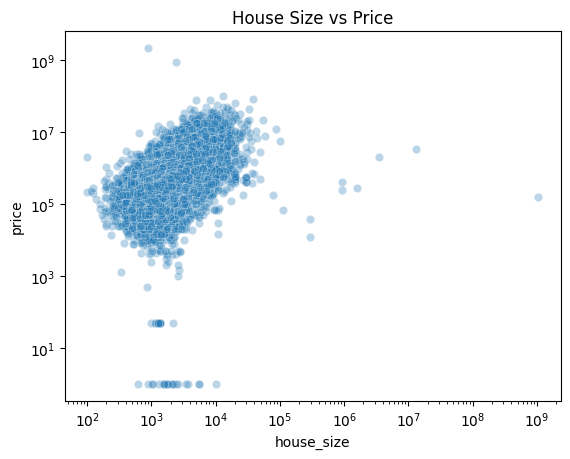

In [25]:


sample = X[
    (X["house_size"] > 0) &
    (y > 0)
].sample(frac=0.1, random_state=42)

sns.scatterplot(
    data=sample,
    x="house_size",
    y=y,
    alpha=0.3
)

plt.xscale("log")
plt.yscale("log")
plt.title("House Size vs Price")
plt.show()

In [26]:
Q1 = X["house_size"].quantile(0.25)
Q3 = X["house_size"].quantile(0.75)
IQR = Q3 - Q1
LowerBound = Q1 - 1.5*Q1
UpperBound = Q3 + 2.5*Q1
Outliers = X[X["house_size"]>UpperBound].nunique()
print("LowerBound: ", LowerBound)
print("UpperBound: ", UpperBound)
print("No. of Outliers: ", Outliers)

LowerBound:  -650.0
UpperBound:  5663.0
No. of Outliers:  brokered_by          10012
status                   3
bed                     88
bath                    76
acre_lot              2600
street               24187
city                  5003
state                   54
zip_code              7990
house_size            6568
years_since_sold      5793
sold_year               61
sold_date_missing        2
dtype: int64


In [27]:
data_outfree = df.drop(Outliers, axis = 0)
data_outfree.dropna(subset = "price", inplace = True)
data_outfree

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,years_since_sold,sold_year,sold_date_missing
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN,NaN,1
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN,NaN,1
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN,NaN,1
5,103378.0,for_sale,179000.0,4.0,3.0,0.46,1850806.0,San Sebastian,Puerto Rico,612.0,2520.0,NaN,NaN,1
6,1205.0,for_sale,50000.0,3.0,1.0,0.20,1298094.0,Ciales,Puerto Rico,639.0,2040.0,NaN,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2226377,23009.0,sold,359900.0,4.0,2.0,0.33,353094.0,Richland,Washington,99354.0,3600.0,4.632444,2022.0,0
2226378,18208.0,sold,350000.0,3.0,2.0,0.10,1062149.0,Richland,Washington,99354.0,1616.0,4.632444,2022.0,0
2226379,76856.0,sold,440000.0,6.0,3.0,0.50,405677.0,Richland,Washington,99354.0,3200.0,4.635181,2022.0,0
2226380,53618.0,sold,179900.0,2.0,1.0,0.09,761379.0,Richland,Washington,99354.0,933.0,4.635181,2022.0,0


In [28]:
Xd = data_outfree.drop("price", axis = 1)
yd = data_outfree["price"]
print(Xd.shape)
print(yd.shape)

(2224828, 13)
(2224828,)


In [29]:
Numerical_Features_d = Xd.select_dtypes(include= "number").columns.to_list()
Categorical_Features_d = Xd.select_dtypes(include = "object").columns.to_list()
print(Numerical_Features_d)
print(Categorical_Features_d)

['brokered_by', 'bed', 'bath', 'acre_lot', 'street', 'zip_code', 'house_size', 'years_since_sold', 'sold_year', 'sold_date_missing']
['status', 'city', 'state']


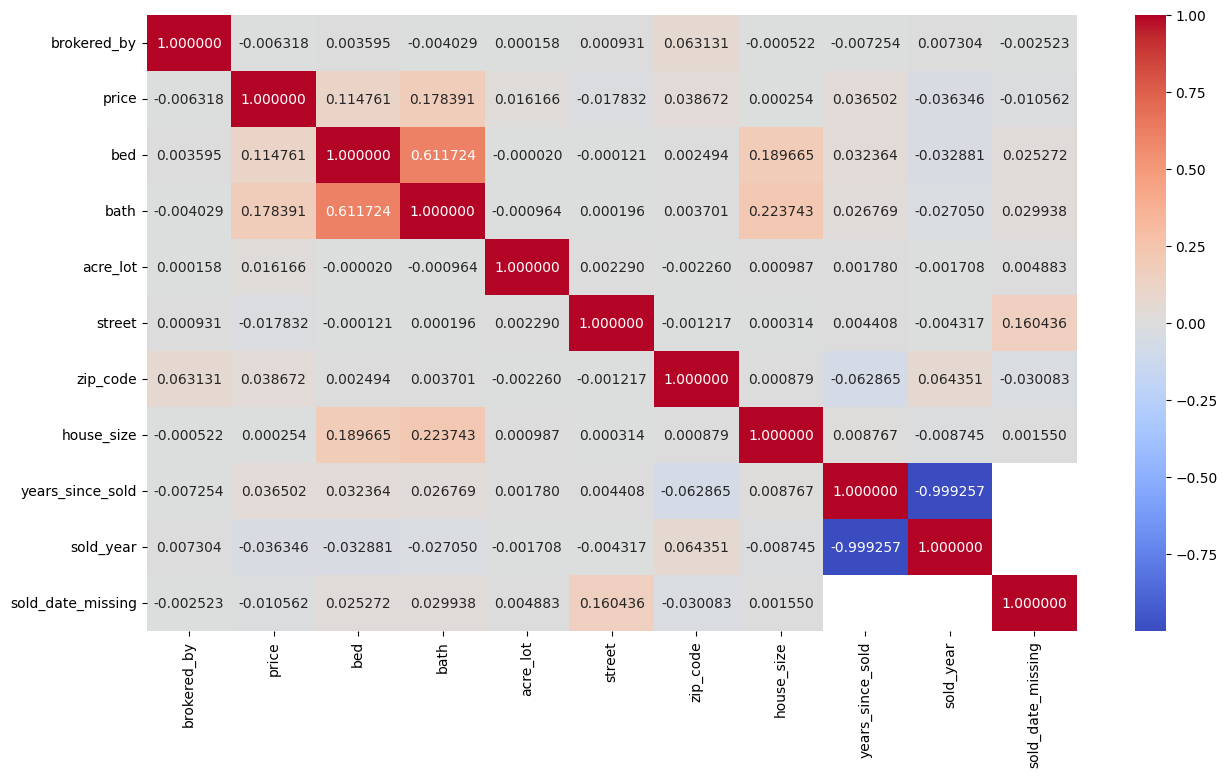

In [30]:
plt.figure(figsize = (15,8))
sns.heatmap(df.select_dtypes(include = "number").corr(), annot = True, cmap = "coolwarm", fmt = ".6f")
plt.show()

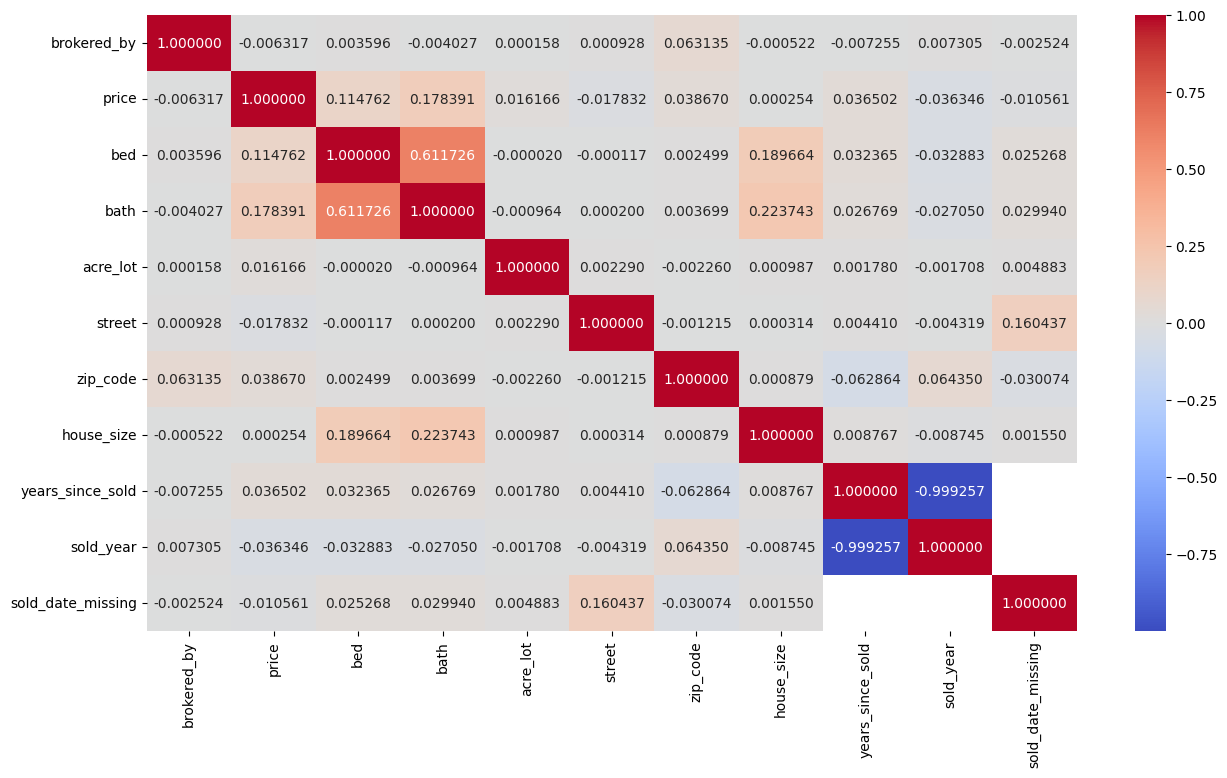

In [31]:
plt.figure(figsize = (15,8))
sns.heatmap(data_outfree.select_dtypes(include = "number").corr(), annot = True, cmap = "coolwarm", fmt = ".6f")
plt.show()

In [32]:
Numerical_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])


Categorical_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

Polynomial_Numerical_Pipeline = Pipeline([
    ("Imputer", SimpleImputer(strategy="median")),
    ("Polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("Scaler", StandardScaler())
])

In [33]:
Transformer = ColumnTransformer([
    ("Numerical",Numerical_Pipeline, Numerical_Features),
    ("Categorical", Categorical_Pipeline, Categorical_Features)
])

Polynomial_Transformer = ColumnTransformer([
        ("Numerical",Polynomial_Numerical_Pipeline, Numerical_Features),
    ("Categorical", Categorical_Pipeline, Categorical_Features)
])



In [34]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15/0.85, random_state=42
)
print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)

Train: (1557388, 13) Validation: (333726, 13) Test: (333727, 13)


In [35]:
Linear_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", LinearRegression())
])

RandomForest_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", RandomForestRegressor())
])

Ridge_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", Ridge())
])

Lasso_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", Lasso())
])

ElasticNet_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", ElasticNet())
])

SGD_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", SGDRegressor())
])

GradientBoosting_Model = Pipeline([
    ("Transformer", clone(Transformer)),
    ("Regressor", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

Polynomial_Model = Pipeline([
    ("Transformer", Polynomial_Transformer),
    ("Regressor", LinearRegression())
])



In [36]:
results = []

def check_score(name, model, prediction):
    train_score = model.score(X_train, y_train)
    validation_score = r2_score(y_val, prediction)
    mae = mean_absolute_error(y_val, prediction)
    rmse = np.sqrt(mean_squared_error(y_val, prediction))
    results.append([name, train_score, validation_score, mae, rmse])
    print(name)
    print('Training R2:', train_score)
    print('Validation R2:', validation_score)
    print('MAE:', mae)
    print('RMSE:', rmse)


In [ ]:
Linear_Model.fit(X_train, y_train)
y_predict = Linear_Model.predict(X_val)
check_score('Linear Regression', Linear_Model, y_predict)


In [ ]:
Ridge_Model.fit(X_train, y_train)
y_predict = Ridge_Model.predict(X_val)
check_score('Ridge Regression', Ridge_Model, y_predict)


In [ ]:
# Lasso_Model.fit(X_train, y_train)
# y_predict = Lasso_Model.predict(X_val)
# check_score('Lasso Regression', Lasso_Model, y_predict)


In [ ]:
ElasticNet_Model.fit(X_train, y_train)
y_predict = ElasticNet_Model.predict(X_val)
check_score('ElasticNet Regression', ElasticNet_Model, y_predict)


In [ ]:
SGD_Model.fit(X_train, y_train)
y_predict = SGD_Model.predict(X_val)
check_score('SGD Regression', SGD_Model, y_predict)

In [ ]:
Polynomial_Model.fit(X_train, y_train)
y_predict = Polynomial_Model.predict(X_val)
check_score('Polynomial Regression', Polynomial_Model, y_predict)


In [ ]:
RandomForest_Model.fit(X_train, y_train)
y_predict = RandomForest_Model.predict(X_val)
check_score('Random Forest', RandomForest_Model, y_predict)


In [ ]:
GradientBoosting_Model.fit(X_train, y_train)
y_predict = GradientBoosting_Model.predict(X_val)
check_score('Gradient Boosting', GradientBoosting_Model, y_predict)


In [ ]:
# XGBoost_Model.fit(X_train, y_train)
# XGBoost_Pred = XGBoost_Model.predict(X_val)
# print('XGBoost Training R2:', XGBoost_Model.score(X_train, y_train))
# print('XGBoost Validation R2:', r2_score(y_val, XGBoost_Pred))


### 10. Compare training vs validation scores

In [ ]:
student_scores = pd.DataFrame(results, columns=['Model','Train R2','Validation R2','MAE','RMSE'])
student_scores = student_scores.sort_values('Validation R2', ascending=False)
display(student_scores)
student_scores.to_csv('realtor_student_scores.csv', index=False)

student_scores.set_index('Model')[['Train R2','Validation R2']].plot(
    kind='bar', figsize=(11,5), rot=45
)
plt.title('Train vs validation R² (look for overfitting)')
plt.ylabel('R² score')
plt.tight_layout()
plt.show()
